# Notebook 62 — Recurrent and Transformer captioning comparison

Image captioning is a **conditional generative** task: given an image representation $I$, the model learns a distribution over possible token sequences, $p(caption\mid I)$. Notebook 29 implemented recurrent captioning from first principles. This final generative-model practice compares that recurrent approach with a causal Transformer decoder.

We use a controlled synthetic dataset of colors and shapes. The input to each decoder is a compact image-feature vector, analogous to features produced by a pretrained CNN or Vision Transformer. This lets us focus on the sequence generator rather than train another visual encoder.

Related material:

- [Notebook 29 — Image captioning with an RNN](29_image_captioning_with_rnn.ipynb)
- [Notebook 54 — Autoregressive models and exact likelihood](54_autoregressive_models_and_exact_likelihood.ipynb)
- [Generative models and likelihood](../notes/13-generative-models/generative-models-and-likelihood.md)
- [Autoregressive generative models](../notes/13-generative-models/autoregressive-generative-models.md)

## Learning goals

- express captioning as conditional autoregressive modeling;
- train recurrent and Transformer decoders on identical data;
- understand how an image representation conditions each architecture;
- construct and interpret a causal attention mask;
- distinguish parallel teacher-forced training from sequential generation;
- compare loss, accuracy, parameter count, and generated captions;
- connect captioning to the earlier autoregressive generative-model practice.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cpu")
print("device:", DEVICE)

device: cpu


## 1. A controlled image-caption dataset

Every example has one color and one shape. Its six-dimensional image feature is the concatenation of two one-hot vectors plus small Gaussian noise:

```text
[red, green, blue, circle, square, triangle]
```

The target caption has the form:

```text
<START> a red circle <END>
```

A real captioning system would replace these handcrafted features with an image encoder output and would encounter many valid captions per image. The simplified dataset gives us an exact correctness criterion.

### Exercise 1 — Construct features and captions

In [2]:
TOKEN_TO_ID = {
    "<PAD>": 0,
    "<START>": 1,
    "<END>": 2,
    "a": 3,
    "red": 4,
    "green": 5,
    "blue": 6,
    "circle": 7,
    "square": 8,
    "triangle": 9,
}
ID_TO_TOKEN = {value: key for key, value in TOKEN_TO_ID.items()}
COLORS = ("red", "green", "blue")
SHAPES = ("circle", "square", "triangle")
VOCABULARY_SIZE = len(TOKEN_TO_ID)
IMAGE_FEATURE_DIM = len(COLORS) + len(SHAPES)


def make_caption_dataset(number_examples, *, feature_noise=0.08, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    color_ids = torch.randint(0, len(COLORS), (number_examples,), generator=generator)
    shape_ids = torch.randint(0, len(SHAPES), (number_examples,), generator=generator)

    # Concatenate color and shape one-hot representations.
    features = torch.cat(
        (F.one_hot(color_ids, len(COLORS)), F.one_hot(shape_ids, len(SHAPES))),
        dim=1,
    ).float()
    features = features + feature_noise * torch.randn(
        features.shape, generator=generator
    )

    captions = torch.empty(number_examples, 5, dtype=torch.long)
    # Fill <START>, 'a', color, shape, and <END> positions.
    captions[:, 0] = TOKEN_TO_ID["<START>"]
    captions[:, 1] = TOKEN_TO_ID["a"]
    captions[:, 2] = color_ids + TOKEN_TO_ID["red"]
    captions[:, 3] = shape_ids + TOKEN_TO_ID["circle"]
    captions[:, 4] = TOKEN_TO_ID["<END>"]
    return features.float(), captions, color_ids, shape_ids


all_features, all_captions, color_ids, shape_ids = make_caption_dataset(1500)
assert all_features.shape == (1500, IMAGE_FEATURE_DIM)
assert all_captions.shape == (1500, 5)
assert torch.all(all_captions[:, 0] == TOKEN_TO_ID["<START>"])
assert torch.all(all_captions[:, -1] == TOKEN_TO_ID["<END>"])

train_features, validation_features = all_features[:1200], all_features[1200:]
train_captions, validation_captions = all_captions[:1200], all_captions[1200:]
print("example feature:", all_features[0].round(decimals=2).tolist())
print("example caption:", " ".join(ID_TO_TOKEN[int(token)] for token in all_captions[0]))

example feature: [0.9200000166893005, 0.10000000149011612, 0.10000000149011612, 0.009999999776482582, 0.8999999761581421, 0.07000000029802322]
example caption: <START> a red square <END>


## 2. One autoregressive objective for both models

Both decoders use the same shifted caption:

```text
input:  <START> a     red    circle
target: a       red   circle <END>
```

With teacher forcing, all correct preceding tokens are available during training. The loss is the sum or average of next-token negative log-probabilities:

$$
-\sum_{t=1}^{T}\log p(c_t\mid I,c_{<t}).
$$

The architectural difference is how each model summarizes $I$ and $c_{<t}$, not what probability objective it learns.

This deliberately repeats several ideas from [Notebook 54 — Autoregressive models and exact likelihood](54_autoregressive_models_and_exact_likelihood.ipynb): shifted inputs and targets, teacher forcing, next-token cross-entropy, causal access to context, and sequential sampling. [Notebook 54](./54_autoregressive_models_and_exact_likelihood.ipynb) introduced those ideas for an unconditional sequence model. Here, the new questions are how an image feature conditions the distribution and how recurrent and Transformer decoders implement the same conditional autoregressive objective.

### Exercise 2 — Shift captions into inputs and targets

In [3]:
def prepare_caption_batch(captions):
    # Remove the final token for inputs and the initial token for targets.
    caption_inputs = captions[:, :-1]
    caption_targets = captions[:, 1:]
    return caption_inputs, caption_targets


example_inputs, example_targets = prepare_caption_batch(all_captions[:2])
assert example_inputs.shape == example_targets.shape == (2, 4)
torch.testing.assert_close(example_inputs[:, 1:], example_targets[:, :-1])
assert torch.all(example_inputs[:, 0] == TOKEN_TO_ID["<START>"])
assert torch.all(example_targets[:, -1] == TOKEN_TO_ID["<END>"])

## 3. Recurrent caption decoder

The recurrent decoder projects the image feature into its initial hidden state:

$$
h_0=W_I I+b_I.
$$

It then processes caption-input embeddings from left to right. Its hidden state carries information about the image and preceding tokens. PyTorch can process the complete teacher-forced sequence in one call, but the recurrence itself still imposes a sequential dependency between time steps.

### Exercise 3 — Implement the recurrent forward pass

In [4]:
class RecurrentCaptionDecoder(nn.Module):
    def __init__(self, model_dim=48):
        super().__init__()
        self.image_projection = nn.Linear(IMAGE_FEATURE_DIM, model_dim)
        self.token_embedding = nn.Embedding(VOCABULARY_SIZE, model_dim)
        self.recurrent_layer = nn.GRU(model_dim, model_dim, batch_first=True)
        self.output_projection = nn.Linear(model_dim, VOCABULARY_SIZE)

    def forward(self, image_features, caption_inputs):
        # Project each image into initial hidden state shape (1, N, D).
        initial_hidden = self.image_projection(image_features).unsqueeze(0)
        # Embed all input tokens, run the GRU, and project all hidden states.
        embedded_tokens = self.token_embedding(caption_inputs)
        hidden_states, _ = self.recurrent_layer(embedded_tokens, initial_hidden)
        return self.output_projection(hidden_states)


rnn_shape_model = RecurrentCaptionDecoder()
shape_inputs, _ = prepare_caption_batch(all_captions[:7])
rnn_shape_logits = rnn_shape_model(all_features[:7], shape_inputs)
assert rnn_shape_logits.shape == (7, 4, VOCABULARY_SIZE)

## 4. Causal attention and the image token

The Transformer receives the projected image as position zero followed by caption-input tokens:

```text
position:  0        1        2     3      4
content:  [IMAGE]  <START>   a    red   circle
predict:             a      red  circle <END>
```

A causal mask prevents each caption position from reading later caption inputs. Position $i$ may attend to positions $0$ through $i$, including the image token, but not to positions greater than $i$. Without this mask, teacher-forced training would leak future words into earlier predictions.

In an additive attention mask, allowed entries are zero and forbidden future entries are $-\infty$, so their probabilities become zero after softmax.

### Exercise 4 — Construct the causal mask

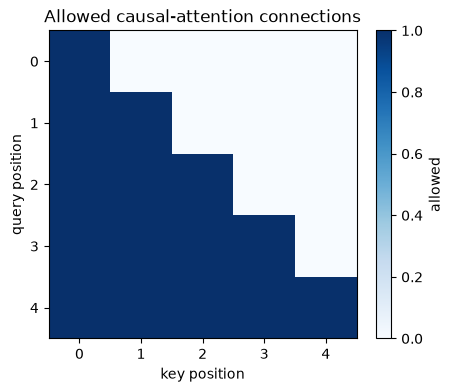

In [5]:
def causal_attention_mask(sequence_length, *, device=None):
    # Allowed entries are zero; forbidden future entries are negative infinity.
    mask = torch.full((sequence_length, sequence_length), -torch.inf, device=device)
    return torch.triu(mask, diagonal=1)


test_mask = causal_attention_mask(5)
assert test_mask.shape == (5, 5)
assert torch.all(test_mask.diagonal() == 0)
assert torch.isneginf(test_mask[0, 1:]).all()
assert torch.all(test_mask[4] == 0)

plt.figure(figsize=(5, 4))
plt.imshow(torch.isfinite(test_mask), cmap="Blues", vmin=0, vmax=1)
plt.xlabel("key position")
plt.ylabel("query position")
plt.title("Allowed causal-attention connections")
plt.colorbar(label="allowed")
plt.show()

## 5. Transformer caption decoder

Unlike the recurrent model, all teacher-forced caption positions can pass through a Transformer layer in parallel. The causal mask restricts information flow, while self-attention lets each position directly combine the image token and all permitted earlier tokens.

We take the outputs corresponding to caption-input positions and project them to next-token logits. The image-token output itself does not predict a word.

### Exercise 5 — Implement the Transformer forward pass

In [6]:
class TransformerCaptionDecoder(nn.Module):
    def __init__(self, model_dim=48, num_heads=4, feed_forward_dim=96, max_caption_length=4):
        super().__init__()
        self.max_caption_length = max_caption_length
        self.image_projection = nn.Linear(IMAGE_FEATURE_DIM, model_dim)
        self.token_embedding = nn.Embedding(VOCABULARY_SIZE, model_dim)
        self.position_embedding = nn.Parameter(
            torch.randn(1, max_caption_length + 1, model_dim) * 0.02
        )
        layer = nn.TransformerEncoderLayer(
            d_model=model_dim,
            nhead=num_heads,
            dim_feedforward=feed_forward_dim,
            dropout=0.0,
            batch_first=True,
            norm_first=True,
        )
        self.transformer = nn.TransformerEncoder(
            layer, num_layers=2, enable_nested_tensor=False
        )
        self.output_projection = nn.Linear(model_dim, VOCABULARY_SIZE)

    def forward(self, image_features, caption_inputs):
        number_tokens = caption_inputs.shape[1]
        if number_tokens > self.max_caption_length:
            raise ValueError("caption input exceeds max_caption_length")
        # Create one image token and embed the caption inputs.
        image_token = self.image_projection(image_features).unsqueeze(1)
        caption_tokens = self.token_embedding(caption_inputs)
        # Concatenate them and add matching learned positions.
        tokens = torch.cat((image_token, caption_tokens), dim=1)
        tokens = tokens + self.position_embedding[:, : tokens.shape[1]]
        # Apply a causal mask to the complete image-plus-caption sequence.
        mask = causal_attention_mask(tokens.shape[1], device=tokens.device)
        encoded = self.transformer(tokens, mask=mask)
        # Position zero is the image; remaining outputs predict next tokens.
        return self.output_projection(encoded[:, 1:])


transformer_shape_model = TransformerCaptionDecoder()
transformer_shape_logits = transformer_shape_model(all_features[:7], shape_inputs)
assert transformer_shape_logits.shape == (7, 4, VOCABULARY_SIZE)

## 6. Train both models under the same objective

For a fair controlled comparison, both models receive the same training batches, use the same mean token cross-entropy, and train with Adam. Equal model width does not imply equal parameter count because their internal operations differ.

### Exercise 6 — Complete the shared training loop

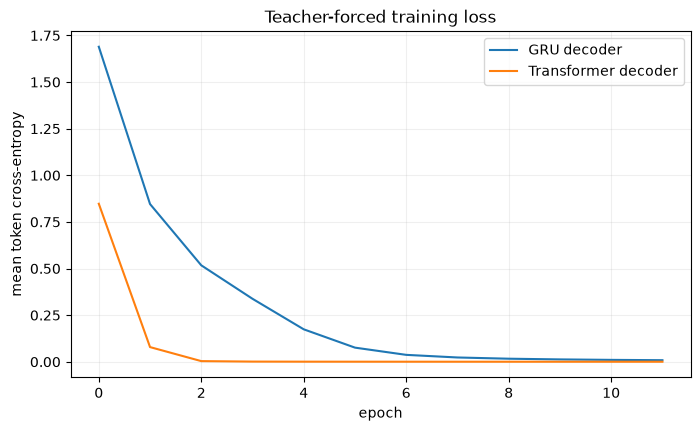

In [12]:
def token_cross_entropy(logits, targets):
    return F.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1))


def train_caption_decoder(model, features, captions, *, epochs=12, batch_size=64, learning_rate=2e-3):
    loader = DataLoader(TensorDataset(features, captions), batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    model.train()

    for _ in range(epochs):
        total_loss = 0.0
        total_examples = 0
        for feature_batch, caption_batch in loader:
            caption_inputs, caption_targets = prepare_caption_batch(caption_batch)
            feature_batch = feature_batch.to(DEVICE)
            caption_inputs = caption_inputs.to(DEVICE)
            caption_targets = caption_targets.to(DEVICE)
            # Calculate logits and mean token cross-entropy.
            logits = model(feature_batch, caption_inputs)
            loss = token_cross_entropy(logits, caption_targets)
            # Update the model.
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(feature_batch)
            total_examples += len(feature_batch)
        history.append(total_loss / total_examples)
    return history


torch.manual_seed(SEED)
rnn_model = RecurrentCaptionDecoder().to(DEVICE)
torch.manual_seed(SEED)
transformer_model = TransformerCaptionDecoder().to(DEVICE)
rnn_history = train_caption_decoder(rnn_model, train_features, train_captions)
transformer_history = train_caption_decoder(
    transformer_model, train_features, train_captions
)
assert np.isfinite(rnn_history).all() and np.isfinite(transformer_history).all()

plt.figure(figsize=(8, 4.5))
plt.plot(rnn_history, label="GRU decoder")
plt.plot(transformer_history, label="Transformer decoder")
plt.xlabel("epoch")
plt.ylabel("mean token cross-entropy")
plt.title("Teacher-forced training loss")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 7. Training is parallel; generation remains autoregressive

During teacher-forced training, both models receive all caption inputs and return logits for every position. The Transformer can calculate its token representations in parallel subject to the causal mask.

During generation, the next token does not yet exist. Both models must repeatedly predict one token and feed it back as part of the next input:

```text
<START> -> a -> red -> circle -> <END>
```

For one shared educational sampler, we rerun each model on the complete prefix. A production recurrent decoder would normally cache its hidden state, while a production Transformer would cache earlier key/value projections.

### Exercise 7 — Implement greedy autoregressive decoding

In [8]:
@torch.no_grad()
def generate_captions(model, image_features, max_length=4):
    model.eval()
    generated = torch.full(
        (len(image_features), 1),
        TOKEN_TO_ID["<START>"],
        dtype=torch.long,
        device=image_features.device,
    )
    finished = torch.zeros(len(image_features), dtype=torch.bool, device=image_features.device)

    for _ in range(max_length):
        # Predict the distribution after the current final prefix token.
        next_logits = model(image_features, generated)[:, -1]
        # Special input-only tokens must not be generated.
        next_logits[:, [TOKEN_TO_ID["<PAD>"], TOKEN_TO_ID["<START>"]]] = -torch.inf
        next_ids = next_logits.argmax(dim=1)
        # Keep <END> fixed for already finished sequences.
        next_ids = torch.where(
            finished, torch.full_like(next_ids, TOKEN_TO_ID["<END>"]), next_ids
        )
        generated = torch.cat((generated, next_ids[:, None]), dim=1)
        finished |= next_ids == TOKEN_TO_ID["<END>"]
        if finished.all():
            break
    return generated[:, 1:]


rnn_generated = generate_captions(rnn_model, validation_features)
transformer_generated = generate_captions(transformer_model, validation_features)
assert rnn_generated.shape[0] == transformer_generated.shape[0] == len(validation_features)
assert rnn_generated.shape[1] <= 4 and transformer_generated.shape[1] <= 4

## 8. Compare captions, accuracy, and capacity

Token accuracy can hide an important failure—for example, a caption might get `a` and `<END>` right while naming the wrong color. We therefore also measure **exact-caption accuracy**, which requires every generated token to match the target.

The synthetic target after `<START>` always has length four, so the comparison does not need padding. Real caption datasets require masks for variable lengths.

### Exercise 8 — Calculate both accuracy measures

In [9]:
def caption_accuracies(generated, target_captions):
    targets = target_captions[:, 1:]
    if generated.shape != targets.shape:
        raise ValueError("generated and target captions must have equal shapes")
    # Calculate accuracy across tokens and exact accuracy across captions.
    matches = generated == targets
    token_accuracy = matches.float().mean().item()
    exact_accuracy = matches.all(dim=1).float().mean().item()
    return token_accuracy, exact_accuracy


def decode_caption(token_ids):
    words = []
    for token_id in token_ids:
        token = ID_TO_TOKEN[int(token_id)]
        if token == "<END>":
            break
        if token not in {"<PAD>", "<START>"}:
            words.append(token)
    return " ".join(words)


rnn_token_accuracy, rnn_exact_accuracy = caption_accuracies(
    rnn_generated, validation_captions
)
transformer_token_accuracy, transformer_exact_accuracy = caption_accuracies(
    transformer_generated, validation_captions
)
number_rnn_parameters = sum(parameter.numel() for parameter in rnn_model.parameters())
number_transformer_parameters = sum(
    parameter.numel() for parameter in transformer_model.parameters()
)

print(
    f"GRU:         {number_rnn_parameters:,} parameters, "
    f"token accuracy={rnn_token_accuracy:.3f}, exact={rnn_exact_accuracy:.3f}"
)
print(
    f"Transformer: {number_transformer_parameters:,} parameters, "
    f"token accuracy={transformer_token_accuracy:.3f}, "
    f"exact={transformer_exact_accuracy:.3f}"
)

for index in range(10):
    expected = decode_caption(validation_captions[index, 1:])
    recurrent = decode_caption(rnn_generated[index])
    transformer = decode_caption(transformer_generated[index])
    print(f"{index:>2} target: {expected:<18} | GRU: {recurrent:<18} | Transformer: {transformer}")

GRU:         15,418 parameters, token accuracy=1.000, exact=1.000
Transformer: 39,466 parameters, token accuracy=1.000, exact=1.000
 0 target: a blue circle      | GRU: a blue circle      | Transformer: a blue circle
 1 target: a green square     | GRU: a green square     | Transformer: a green square
 2 target: a green circle     | GRU: a green circle     | Transformer: a green circle
 3 target: a blue square      | GRU: a blue square      | Transformer: a blue square
 4 target: a green square     | GRU: a green square     | Transformer: a green square
 5 target: a blue square      | GRU: a blue square      | Transformer: a blue square
 6 target: a blue square      | GRU: a blue square      | Transformer: a blue square
 7 target: a green square     | GRU: a green square     | Transformer: a green square
 8 target: a blue triangle    | GRU: a blue triangle    | Transformer: a blue triangle
 9 target: a blue square      | GRU: a blue square      | Transformer: a blue square


## 9. What the comparison does and does not establish

One small synthetic experiment cannot establish that one architecture is universally better. Results depend on model size, optimization, data, caption length, image encoder quality, and decoding strategy. The durable comparison is structural:

| Property | Recurrent decoder | Transformer decoder |
| --- | --- | --- |
| Context representation | Updated hidden state | Causal attention over permitted tokens |
| Image conditioning here | Initial hidden state | Image token available through attention |
| Teacher-forced training | Recurrent dependency across time | Token positions processed in parallel |
| Autoregressive generation | Sequential; cache hidden state | Sequential; cache keys and values |
| Long-range token access | Indirect through recurrent state | Direct attention path |
| Typical scaling behavior | Simple and efficient for smaller sequences | Highly parallel training and strong scaling |

Greedy decoding always selects the most likely next token. Sampling instead draws from the predicted distribution and can produce varied valid captions, but it can also introduce errors. Beam search keeps several promising prefixes. Those decoding choices apply to both recurrent and Transformer autoregressive models.

For a broader comparison, see [Generative-model families: a compact comparison](../notes/14-generative-models/generative-model-families-comparison.md).

## Reflection

Answer briefly after completing and running the notebook.

1. Why is image captioning a conditional generative task rather than ordinary classification?

   **Answer:** Image captioning generates a sequence from a distribution conditioned on image features. It is not ordinary classification because it produces multiple dependent tokens, and an image may have several valid captions.

2. What is shared by the recurrent and Transformer training objectives?

   **Answer:** Both models use teacher forcing and minimize next-token cross-entropy for the same conditional autoregressive likelihood. They differ in how they represent previous tokens and image information.

3. How does the image feature influence each decoder in this notebook?

   **Answer:** The recurrent decoder projects the image features into its initial hidden state. The Transformer projects the image into an image token that participates in attention together with the caption tokens.

4. Why would removing the Transformer's causal mask make its training result misleading?

   **Answer:** Without the causal mask, each position could inspect future target tokens during training, including information unavailable during generation. The reported loss and accuracy would therefore be misleading.

5. Why can Transformer training process token positions in parallel while generation remains sequential?

   **Answer:** During training, the complete shifted input sequence is known, so all positions can be processed simultaneously under a causal mask. During generation, the next token is unknown until the preceding token has been generated.

6. What does exact-caption accuracy reveal that token accuracy may hide?

   **Answer:** Token accuracy can remain high when a model predicts easy tokens such as a and <END> but gets the color or shape wrong. Exact-caption accuracy counts a caption as correct only when every target token matches.

7. What conclusions can and cannot be drawn from the accuracy difference in this experiment?

   **Answer:** Both models can solve this simple synthetic task. Because the dataset has only nine underlying color–shape combinations and both models reached perfect accuracy, the experiment does not establish that either architecture is generally superior. Real results would depend on dataset complexity, model capacity, optimization, and decoding strategy.

8. Using the linked generative-model comparison note, which family would you choose for each of these priorities: exact likelihood, one-pass sampling, an organized latent space, and iterative high-quality generation?

   **Answer:** Use an autoregressive model for exact factorized likelihood, a GAN for one-pass sampling, a VAE for an organized latent space, and diffusion or rectified flow for iterative high-quality generation. These priorities are not absolute because modern systems often combine multiple families.